# MAE, VAE, Diffusion & RAG

In [1]:
!pip install -q torch transformers datasets diffusers rouge-score matplotlib pillow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import math
import json
import csv
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from PIL import Image

from datasets import load_dataset
from diffusers import UNet2DModel
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM
from rouge_score import rouge_scorer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu | Device: cpu


In [3]:
UHAT_DIR = "/content/data/uhat"
if not os.path.exists(UHAT_DIR) or not os.listdir(UHAT_DIR):
    os.makedirs(UHAT_DIR, exist_ok=True)
    !wget -q --show-progress -O /tmp/uhat_data.zip "https://zenodo.org/records/3670611/files/data.zip?download=1"
    !unzip -q /tmp/uhat_data.zip -d {UHAT_DIR}
    !rm -f /tmp/uhat_data.zip
    print("UHaT extracted to", UHAT_DIR)
else:
    print("UHaT already present in", UHAT_DIR)

/tmp/uhat_data.zip  100%[===================>]  31.33M  5.22MB/s    in 12s     
UHaT extracted to /content/data/uhat


In [4]:
def show_grid(images, nrow=8, titles=None):
    """images: (N, C, H, W) in [0, 1]. Displays an nrow-wide grid inline."""
    images = images.detach().cpu().clamp(0, 1)
    n = images.shape[0]
    rows = (n + nrow - 1) // nrow
    fig, axes = plt.subplots(rows, nrow, figsize=(1.4 * nrow, 1.4 * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            img = images[i].permute(1, 2, 0).numpy()
            ax.imshow(img.squeeze(-1) if img.shape[-1] == 1 else img, cmap="gray", vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## Starter: EuroSAT (Part A)

In [5]:
EUROSAT_REPO = "blanchon/EuroSAT_RGB"
CLASS_NAMES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
               "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
PATCH = 8  # 64 / 8 = 8 x 8 = 64 patches per image


def load_eurosat_split(split):
    """split in {'train', 'validation', 'test'}.
    Returns images (N, 3, 64, 64) float32 in [0, 1] and labels (N,) int64."""
    ds = load_dataset(EUROSAT_REPO, split=split)
    imgs = np.stack([np.asarray(im.convert("RGB"), dtype=np.uint8) for im in ds["image"]])
    images = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.0
    labels = torch.tensor(ds["label"], dtype=torch.long)
    return images, labels


def few_label_indices(labels, per_class=16, seed=42):
    """Indices of a fixed labelled subset: `per_class` images of each class."""
    rng = np.random.default_rng(seed)
    idx = []
    for c in range(len(CLASS_NAMES)):
        members = np.flatnonzero(labels.numpy() == c)
        idx.extend(rng.choice(members, size=per_class, replace=False).tolist())
    return torch.tensor(sorted(idx))


def patchify(images, p=PATCH):
    """(N, C, H, W) -> (N, L, p*p*C) with L = (H/p)*(W/p), patches in row-major order."""
    N, C, H, W = images.shape
    x = images.reshape(N, C, H // p, p, W // p, p)
    x = x.permute(0, 2, 4, 3, 5, 1)
    return x.reshape(N, (H // p) * (W // p), p * p * C)


def unpatchify(patches, p=PATCH, C=3):
    """Inverse of patchify: (N, L, p*p*C) -> (N, C, H, W)."""
    N, L, _ = patches.shape
    h = w = int(L ** 0.5)
    x = patches.reshape(N, h, w, p, p, C).permute(0, 5, 1, 3, 2, 4)
    return x.reshape(N, C, h * p, w * p)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.38k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  105MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

EuroSAT train (16200, 3, 64, 64) test (5400, 3, 64, 64)
few-label subset: 160 images; patches per image: (8, 64, 192)


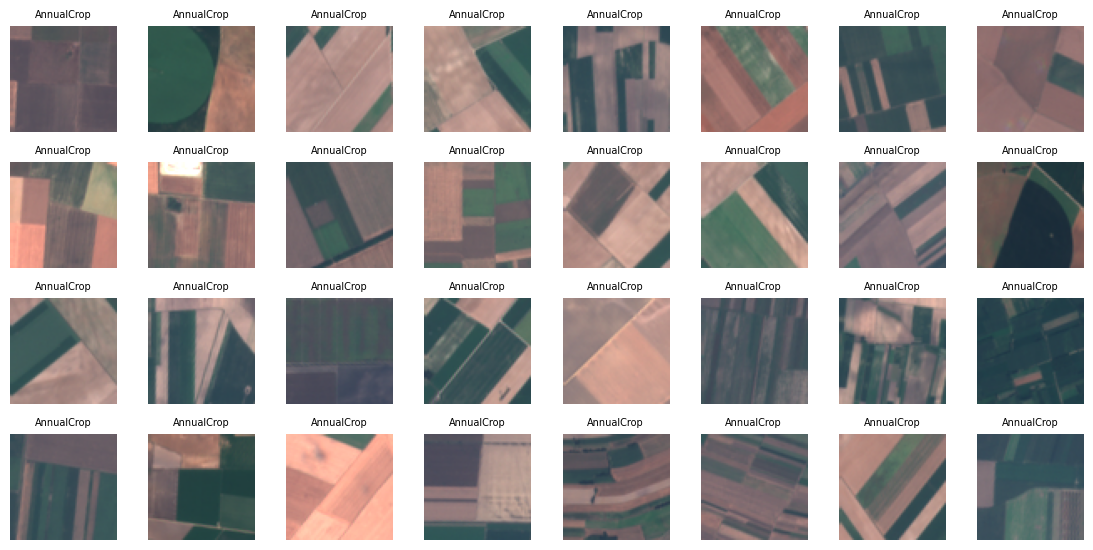

In [6]:
x_tr, y_tr = load_eurosat_split("train")
x_te, y_te = load_eurosat_split("test")
few = few_label_indices(y_tr)
p = patchify(x_tr[:8])
print("EuroSAT train", tuple(x_tr.shape), "test", tuple(x_te.shape))
print("few-label subset:", len(few), "images; patches per image:", tuple(p.shape))
assert torch.equal(unpatchify(p), x_tr[:8])
show_grid(x_tr[:32], nrow=8, titles=[CLASS_NAMES[i] for i in y_tr[:32]])

## Starter: UHaT Characters (Parts B & C)

In [7]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def _find_split_dir(root, kind, split):
    """Find the folder whose name mentions both `kind` and `split` with class subfolders."""
    for d in sorted(Path(root).rglob("*")):
        name = d.name.lower()
        if d.is_dir() and kind in name and split in name:
            if any(c.is_dir() for c in d.iterdir()):
                return d
    found = [str(d) for d in Path(root).rglob("*") if d.is_dir()][:20]
    raise FileNotFoundError(f"No '{kind}'/'{split}' folder under {root}. Folders seen: {found}")


def load_uhat_characters(root=UHAT_DIR, split="train", class_names=None):
    """Returns images (N, 1, 28, 28) float32 in [0, 1] with WHITE strokes on BLACK."""
    split_dir = _find_split_dir(root, "char", split)
    if class_names is None:
        class_names = sorted(c.name.lower() for c in split_dir.iterdir() if c.is_dir())
    index = {name: i for i, name in enumerate(class_names)}
    images, labels = [], []
    for cdir in sorted(split_dir.iterdir()):
        if not cdir.is_dir() or cdir.name.lower() not in index:
            continue
        for f in sorted(cdir.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                im = Image.open(f).convert("L").resize((28, 28))
                images.append(np.asarray(im, dtype=np.float32) / 255.0)
                labels.append(index[cdir.name.lower()])
    x = torch.from_numpy(np.stack(images)).unsqueeze(1)
    flip = x.mean(dim=(1, 2, 3)) > 0.5
    x[flip] = 1.0 - x[flip]
    return x, torch.tensor(labels, dtype=torch.long), class_names

UHaT train (28328, 1, 28, 28) test (4747, 1, 28, 28) classes: 40
class names: ['alif', 'alif mad aa', 'ayn', 'baa', 'bari yaa', 'cheey', 'choti yaa', 'daal', 'dhaal', 'faa', 'gaaf', 'ghain', 'haa1', 'haa2', 'haa3', 'hamza', 'jeem', 'kaaf', 'khaa', 'laam', 'meem', 'noon', 'noonghunna', 'paa', 'qaaf', 'raa', 'rhraa', 'seen', 'seey', 'sheen', 'swaad', 'taa', 'ttaa', 'twa', 'waw', 'zaaa', 'zaal', 'zhaa', 'zwaa', 'zwaad']


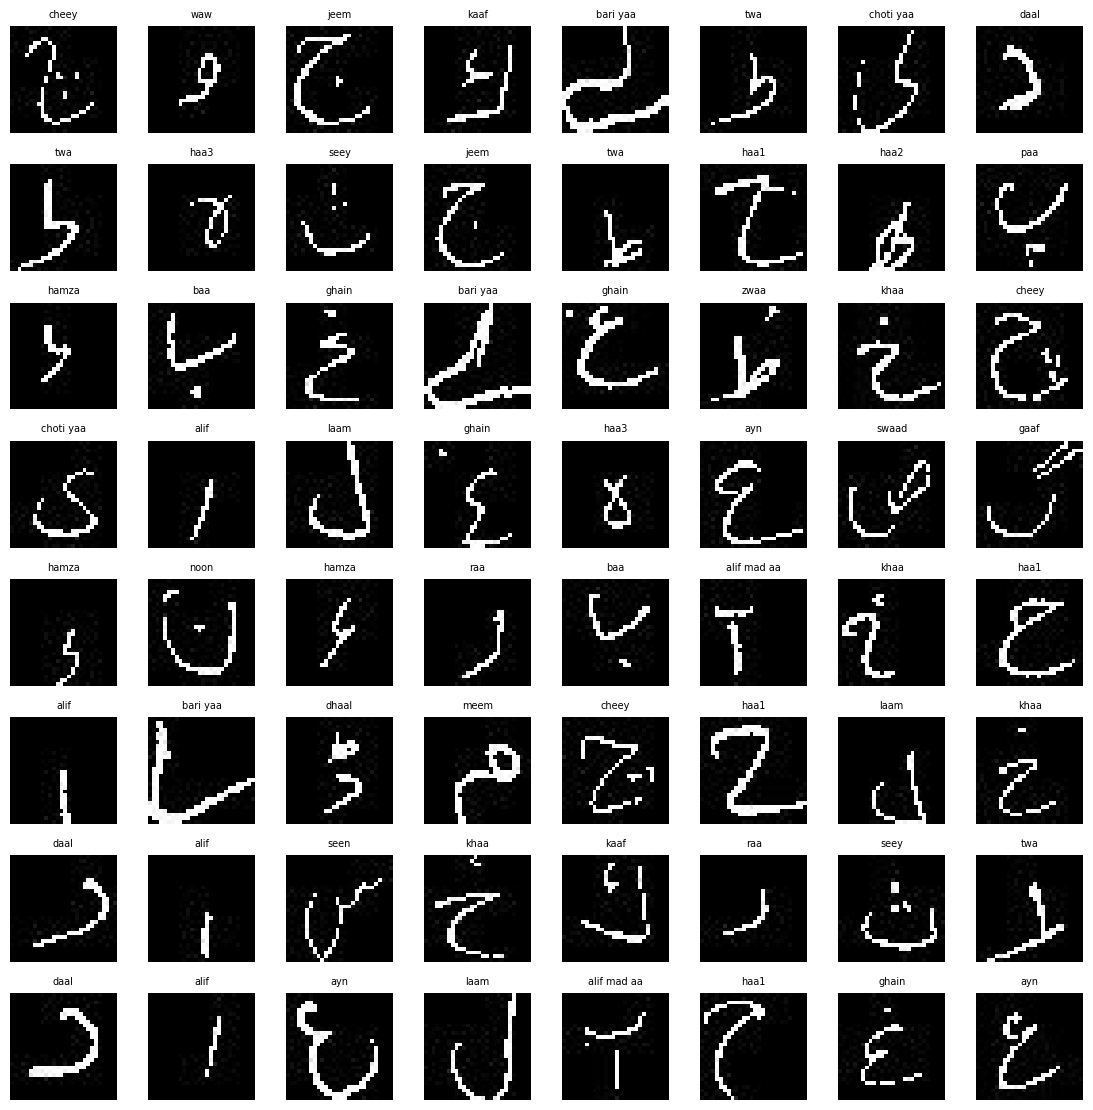

In [8]:
c_tr, l_tr, names = load_uhat_characters(split="train")
c_te, l_te, _ = load_uhat_characters(split="test", class_names=names)
print("UHaT train", tuple(c_tr.shape), "test", tuple(c_te.shape), "classes:", len(names))
print("class names:", names)
pick = torch.randperm(len(c_tr))[:64]
show_grid(c_tr[pick], nrow=8, titles=[names[i] for i in l_tr[pick]])

## Starter: BioASQ (Part D)

In [9]:
BIOASQ_REPO = "enelpol/rag-mini-bioasq"


def load_corpus():
    """Returns {passage_id (int): passage text (str)} for all 40k abstracts."""
    ds = load_dataset(BIOASQ_REPO, "text-corpus")
    split = list(ds.keys())[0]
    return {int(r["id"]): r["passage"] for r in ds[split] if r["passage"]}


def load_questions(split="test", corpus=None):
    """Returns a list of dicts: {qid, question, answer, relevant_ids}."""
    ds = load_dataset(BIOASQ_REPO, "question-answer-passages", split=split)
    out = []
    for r in ds:
        rel = [int(i) for i in r["relevant_passage_ids"]]
        if corpus is not None:
            rel = [i for i in rel if i in corpus]
        if rel:
            out.append({"qid": int(r["id"]), "question": r["question"],
                        "answer": r["answer"], "relevant_ids": rel})
    return out

In [10]:
corpus = load_corpus()
qs = load_questions("test", corpus)
print("BioASQ corpus:", len(corpus), "abstracts; test questions:", len(qs))
print("example:", qs[0]["question"], "| relevant ids:", qs[0]["relevant_ids"][:5])

README.md:   0%|          | 0.00/1.76k [00:00<?, ?B/s]

text-corpus/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 35.3MB            

text-corpus/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/40181 [00:00<?, ? examples/s]

question-answer-passages/train-00000-of-(…): reconstructing file:   0%|          |  0.00B / 1.12MB            

question-answer-passages/train-00000-of-(…): downloading bytes:           |  0.00B            

question-answer-passages/test-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  187kB            

question-answer-passages/test-00000-of-0(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4012 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/707 [00:00<?, ? examples/s]

BioASQ corpus: 40181 abstracts; test questions: 707
example: Is capmatinib effective for glioblastoma? | relevant ids: [31776899]
